# Construção VGG Quaterniônica

Bibliotecas utilizadas

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
import tensorflow.keras as kr
from tensorflow.keras.layers import Layer
from tensorflow.keras import activations, initializers, regularizers
from tensorflow.keras import layers, models
from tensorflow.keras.initializers import RandomUniform

In [ ]:
import requests
import os
url = "https://raw.githubusercontent.com/mevalle/v-nets/main/V_Nets.py"
response = requests.get(url)

if response.status_code == 200:
    with open("V_Nets.py", "wb") as f:
        f.write(response.content)
    print("V_Nets.py downloaded successfully.")
else:
    print(f"Failed to download V_Nets.py. Status code: {response.status_code}")

V_Nets.py downloaded successfully.


In [ ]:
from V_Nets import get_algebra, print_algebra
from V_Nets import V_Conv2D
from V_Nets import V_Dense

### Base de dados - BloodMNIST

In [ ]:
# !pip install medmnist
# from medmnist import BloodMNIST

In [ ]:
# im_size = 64

# train_dataset = BloodMNIST(split='train', download=True, as_rgb=True, size=im_size)
# x_train, y_train = train_dataset.imgs, train_dataset.labels

# validation_dataset = BloodMNIST(split='val', download=True, as_rgb=True, size=im_size)
# x_val, y_val = validation_dataset.imgs, validation_dataset.labels

# test_dataset = BloodMNIST(split='test', download=True, as_rgb=True, size=im_size)
# x_test, y_test = test_dataset.imgs, test_dataset.labels

# print("Training dataset loaded:", train_dataset)
# print("Validation dataset loaded:", validation_dataset)
# print("Test dataset loaded:", test_dataset)

### Base de dados - CIFAR10

In [ ]:
from tensorflow.keras.datasets import cifar10
from sklearn.model_selection import train_test_split

# Carregar os conjuntos de treino e teste.
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

# Separar 10% do conjunto de treino para validação.
x_train, x_val, y_train, y_val = train_test_split(
    x_train,
    y_train,
    test_size=0.1,
    random_state=42,
    stratify=y_train.ravel()
)

print('Treino:', x_train.shape, y_train.shape)
print('Validação:', x_val.shape, y_val.shape)
print('Teste:', x_test.shape, y_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2105s 12us/step
Treino: (45000, 32, 32, 3) (45000, 1)
Validação: (5000, 32, 32, 3) (5000, 1)
Teste: (10000, 32, 32, 3) (10000, 1)


## Max Pooling 2D Vetorial

A ideia é criar o Max Pooling 2D vetorial para trabalhar com álgebras hipercomplexas (dimensão da álgebra maior que 1).

Enquanto o Max Pooling 2D tradicional (da API do Keras) escolhe o máximo separadamente a cada componente escalar de cada hipercomplexo, o Max Pooling 2D Vetorial trata cada hipercomplexo como uma unidade, e dessa forma, escolhe o hipercomplexo com maior norma euclidiana calculada pelas suas componentes para cada canal (referência utilizada: Shen, W. et al. 3D-Rotation-Equivariant Quaternion Neural Networks).

Acabou gerando um resultado inferior à aplicação da função do Keras, e portanto, não foi utilizada nas redes.

In [ ]:
class V_MaxPooling2D(layers.Layer):

    def __init__(
        self,
        pool_size=(2, 2),
        strides=None,
        padding='VALID',
        algdim=4,
        **kwargs
    ):
        super().__init__(**kwargs)

        self.pool_size = pool_size
        if strides is not None:
          self.strides = strides
        else:
          self.strides = pool_size

        self.padding = padding
        self.algdim = algdim

    def call(self, inputs):
      shape = tf.shape(inputs)
      batch = shape[0]
      altura = shape[1]
      largura = shape[2]
      canais = shape[3]
      C = canais // self.algdim #divisão inteira do num de canais por 4

      x = tf.reshape(
      inputs,
      [batch, altura, largura, self.algdim, C]) #x passa de [batch,altura,largura,canais] -> [batch,altura,largura,dim,C]

      x = tf.transpose(x, perm=[0, 1, 2, 4, 3]) #matrizes C x dim

      norma = tf.norm(x, axis=-1) #vetor com as normas de cada elemento de C

      #Construção do max pooling 2D vetorial. Retorna os valores máximos encontrados em cada janela em pooled e o índice desses valores em indices.
      #pooled.shape, indices.shape = (batch,altura/pool_size[0],largura/pool_size[1],C)
      pooled, indices = tf.nn.max_pool_with_argmax(
          norma,
          ksize=[1, self.pool_size[0], self.pool_size[1], 1],
          strides=[1, self.strides[0], self.strides[1], 1],
          padding=self.padding,
          include_batch_in_index=True
      )

      #reorganizar as dimensões de x
      x_flat = tf.reshape(x, [-1, self.algdim])

      selected = tf.gather(x_flat, indices)

      selected = tf.transpose(selected, perm=[0, 1, 2, 4, 3])

      shape_saida = tf.shape(selected)

      outputs = tf.reshape(
          selected,
          [shape_saida[0], shape_saida[1], shape_saida[2], canais]
      )

      return outputs


Álgebra dos quatérnios

In [ ]:
Q = get_algebra('quaternions')
print_algebra(Q)

Bilinear form of the 0-th component.
[[ 1.  0.  0.  0.]
 [ 0. -1.  0.  0.]
 [ 0.  0. -1.  0.]
 [ 0.  0.  0. -1.]]
Bilinear form of the 1-th component.
[[ 0.  1.  0.  0.]
 [ 1.  0.  0.  0.]
 [ 0.  0.  0.  1.]
 [ 0.  0. -1.  0.]]
Bilinear form of the 2-th component.
[[ 0.  0.  1.  0.]
 [ 0.  0.  0. -1.]
 [ 1.  0.  0.  0.]
 [ 0.  1.  0.  0.]]
Bilinear form of the 3-th component.
[[ 0.  0.  0.  1.]
 [ 0.  0.  1.  0.]
 [ 0. -1.  0.  0.]
 [ 1.  0.  0.  0.]]


Dimensões de entrada usando MNIST

In [ ]:
# print('Dimensão da álgebra dos Quatérnios =', Q.shape[-1])
# input_shape_q = (64,64, 4)
# print(input_shape_q)

Dimensões de entrada usando CIFAR10


In [ ]:
print('Dimensão da álgebra dos Quatérnios =', Q.shape[-1])
input_shape_q = (32,32, 4)
print(input_shape_q)

Dimensão da álgebra dos Quatérnios = 4
(32, 32, 4)


## VGG Real

In [ ]:
def build_real_vgg(input_shape=(32,32,3), num_classes=10):
    inp = layers.Input(shape=input_shape)
    x = kr.layers.RandomFlip("horizontal_and_vertical")(inp)
    x = kr.layers.RandomRotation(0.9)(x)

    x = layers.Conv2D(32, kernel_size=(3, 3), activation="relu", padding = 'same')(x)
    x = kr.layers.MaxPooling2D(pool_size=(2, 2))(x)

    x = layers.Conv2D(64, kernel_size=(3, 3), activation="relu", padding = 'same')(x)
    x = kr.layers.MaxPooling2D()(x)

    x = layers.Conv2D(128, kernel_size=(3, 3), activation="relu", padding = 'same')(x)
    x = kr.layers.MaxPooling2D()(x)

    x = layers.Conv2D(128, kernel_size=(3, 3), activation="relu", padding = 'same')(x)
    x = kr.layers.MaxPooling2D()(x)

    x = layers.Flatten()(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(num_classes, activation='softmax')(x)

    return models.Model(inp, out, name='RealVGG')

In [ ]:
real_model = build_real_vgg()
real_model.summary()
print('Parâmetros (real):', real_model.count_params())

Model: "RealVGG"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 32, 32, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 4, 4, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 2, 2, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 245,962 (960.79 KB)

 Trainable params: 245,962 (960.79 KB)

 Non-trainable params: 0 (0.00 B)

Parâmetros (real): 245962


## VGG Hipercomplexa


In [ ]:
def build_quat_vgg(input_shape=input_shape_q, num_classes=10, algebra=Q):
    inp = layers.Input(shape=input_shape)
    x = kr.layers.RandomFlip("horizontal_and_vertical")(inp)
    x = kr.layers.RandomRotation(0.9)(x)

    x = V_Conv2D(8, kernel_size=(3, 3), activation="relu", padding='same', algebra=algebra)(x)
    x = kr.layers.MaxPooling2D()(x)

    x = V_Conv2D(16, kernel_size=(3, 3), activation="relu", padding='same', algebra=algebra)(x)
    x = kr.layers.MaxPooling2D()(x)

    x = V_Conv2D(32, kernel_size=(3, 3), activation="relu", padding='same', algebra=algebra)(x)
    x = kr.layers.MaxPooling2D()(x)

    x = V_Conv2D(32, kernel_size=(3, 3), activation="relu", padding='same', algebra=algebra)(x)
    x = kr.layers.MaxPooling2D()(x)

    x = layers.Flatten()(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(num_classes, activation='softmax')(x)

    return models.Model(inp, out, name='QuaternionVGG')

In [ ]:
quat_model = build_quat_vgg()
quat_model.summary()
print('Parâmetros (quaternion):', quat_model.count_params())

Model: "QuaternionVGG"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 32, 32, 4)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip_1 (RandomFlip)      │ (None, 32, 32, 4)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_1               │ (None, 32, 32, 4)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ v__conv2d (V_Conv2D)            │ (None, 32, 32, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ v__conv2d_1 (V_Conv2D)          │ (None, 16, 16, 64)     │         4,672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ v__conv2d_2 (V_Conv2D)          │ (None, 8, 8, 128)      │        18,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ v__conv2d_3 (V_Conv2D)          │ (None, 4, 4, 128)      │        36,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 2, 2, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 65,674 (256.54 KB)

 Trainable params: 65,674 (256.54 KB)

 Non-trainable params: 0 (0.00 B)

Parâmetros (quaternion): 65674


### Acertando as dimensões da entrada e normalizando



In [ ]:
def aumenta_dimensao(x):
    zeros = np.zeros(
    (x.shape[0], x.shape[1], x.shape[2], 1),
    dtype=x.dtype
    )
    return np.concatenate([zeros, x], axis=-1)

In [ ]:
x_train_real = x_train.astype(np.float32) / 255.0
x_test_real  = x_test.astype(np.float32) / 255.0
x_val_real   = x_val.astype(np.float32) / 255.0
print(x_train_real.shape, x_test_real.shape, x_val_real.shape)

x_train_q = aumenta_dimensao(x_train_real)
x_test_q  = aumenta_dimensao(x_test_real)
x_val_q = aumenta_dimensao(x_val_real)
print(x_train_q.shape, x_test_q.shape, x_val_q.shape)

x_train_a = aumenta_dimensao(x_train_real)
x_test_a  = aumenta_dimensao(x_test_real)
x_val_a = aumenta_dimensao(x_val_real)
print(x_train_a.shape, x_test_a.shape, x_val_a.shape)

(45000, 32, 32, 3) (10000, 32, 32, 3) (5000, 32, 32, 3)
(45000, 32, 32, 4) (10000, 32, 32, 4) (5000, 32, 32, 4)
(45000, 32, 32, 4) (10000, 32, 32, 4) (5000, 32, 32, 4)


### Vetorização das classes dos dados

In [ ]:
y_train = y_train.ravel()
y_test = y_test.ravel()
y_val = y_val.ravel()
print(y_train.shape, y_test.shape, y_val.shape)

(45000,) (10000,) (5000,)


### Treino VGGs

In [ ]:
def treinar_modelo(modelo, x_train, y_train, x_val, y_val,
                   nome, epochs=50, batch_size=128):

    modelo.compile(
        optimizer = kr.optimizers.Adam(
        learning_rate=1e-4
),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    print(f"\nTreinando modelo: {nome}")

    historico = modelo.fit(
        x_train,
        y_train,
        epochs=epochs,
        batch_size=batch_size,
        validation_data=(x_val, y_val),
        verbose=2
    )

    return historico

In [ ]:
#historico_real = treinar_modelo(real_model, x_train_real, y_train, x_val_real, y_val, 'Real')

In [ ]:
#historico_quat = treinar_modelo(quat_model, x_train_q, y_train, x_val_q, y_val, 'Quaternios')

Resultado dos testes

In [ ]:
# loss_real, acc_real = real_model.evaluate(
#     x_test_real,
#     y_test
# )

In [ ]:
# loss_quat, acc_quat = quat_model.evaluate(
#     x_test_q,
#     y_test
# )

# Construção da PHVGG

## PHC Layer - Camada de Convolução Parametrizada Hipercomplexa

In [ ]:
class PHConv2D(V_Conv2D):

    def __init__(self, *args, algebra=Q, **kwargs):
        if isinstance(algebra, (str, kr.initializers.Initializer)): #caso algebra = uniform
            algebra_base = np.zeros((4, 4, 4), dtype=np.float32) #n=4 para V_Conv2D trabalhar com álgebra de dimensão 4.
            algebra_inicial = kr.initializers.get(algebra)
        else: #caso algebra = quaternion
            algebra_base = np.array(algebra, dtype=np.float32, copy=True)
            algebra_inicial = kr.initializers.Constant(algebra_base)

        super().__init__(
            *args,
            algebra=algebra_base,
            **kwargs
        )

        self.algebra_inicial = algebra_inicial
        self.algebra_shape = algebra_base.shape

    def build(self, input_shape):

        #Agora a álgebra passa a ser treinável.
        #A_1, A_2, A_3, A_4 ∈ R^(4x4), onde self.algebra[:, :, i] = A_i
        self.algebra = self.add_weight(
            name="algebra",
            shape=self.algebra_shape,
            initializer=self.algebra_inicial,
            trainable=True,
            dtype=self.dtype
        )

        # Todo o restante continua exatamente igual ao V_Conv2D
        super().build(input_shape)

    def call(self, inputs):
        #produto de kronecker W = A_i x F_i, onde A_i e F_i são tensores
        W = sum([
            tf.experimental.numpy.kron(
                tf.reshape(
                    self.algebra[:, :, k],
                    (1, 1, self.algdim, self.algdim) #(4,4)->(1,1,4,4) (para compatibilidade de dimensão com F_i)
                ),
                self.kernel[:, :, :, :, k] #kernel.shape = \[h_f, w_f, C_in/4,f,4]
            )
            for k in range(self.algdim)
        ])
        #convolução
        outputs = self.convolution_op(
            inputs,
            kernel=tf.cast(W, dtype=self.dtype),
        )
        #correção para uso de bias
        if self.use_bias:
            if self.data_format == "channels_last":
                bias_shape = (1,) * (self.rank + 1) + (
                    self.filters * self.algdim,
                )
            else:
                bias_shape = (
                    1,
                    self.filters * self.algdim
                ) + (1,) * self.rank

            bias = tf.reshape(self.bias, bias_shape)
            outputs += bias

        #verifica se chama função de ativação na saída
        if self.activation is not None:
            return self.activation(outputs)

        return outputs

## PHVGG

Mesma estrutura das outras redes, para comparação justa.

In [ ]:

def build_PHVgg(input_shape=input_shape_q, num_classes=10, algebra=Q):

    inp = layers.Input(shape=input_shape)

    x = kr.layers.RandomFlip("horizontal_and_vertical")(inp)
    x = kr.layers.RandomRotation(0.9)(x)

    x = PHConv2D(8, kernel_size=(3, 3), activation="relu", padding='same', algebra=algebra)(x)
    x = kr.layers.MaxPooling2D()(x)

    x = PHConv2D(16, kernel_size=(3, 3), activation="relu", padding='same', algebra=algebra)(x)
    x = kr.layers.MaxPooling2D()(x)

    x = PHConv2D(32, kernel_size=(3, 3), activation="relu", padding='same', algebra=algebra)(x)
    x = kr.layers.MaxPooling2D()(x)

    x = PHConv2D(32, kernel_size=(3, 3), activation="relu", padding='same', algebra=algebra)(x)
    x = kr.layers.MaxPooling2D()(x)

    x = layers.Flatten()(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(
        num_classes,
        activation='softmax'
    )(x)

    return models.Model(inp, out, name='PHVGG')

### Exibição das álgebras aprendidas

Cada camada PHConv2D aprende um tensor algebra de formato (4, 4, 4), que representa quatro matrizes 4×4: A_1, A_2, A_3 e A_4. A função abaixo lê os valores atuais dos pesos, imprime todas essas matrizes e retorna um DataFrame (uma linha para cada matriz) para eventual exportação.

**Importante:** a extração deve ser feita depois do treinamento e antes da exclusão do modelo. Os pesos das execuções passadas não estão armazenados no arquivo .ipynb; as saídas antigas do notebook não podem ser usadas para recuperar suas matrizes aprendidas.


In [ ]:
import pandas as pd
import numpy as np


def extrair_algebras(modelo, nome_modelo='PHVGG', rodada=None, exibir=True, casas_decimais=4):
    """Exibe e organiza as matrizes A_k aprendidas em cada PHConv2D.

    Retorna um DataFrame com uma linha por matriz 4x4, contendo seus 16 valores.
    """
    camadas_ph = []

    for camada in modelo.layers:
      if isinstance(camada, PHConv2D): #verifica se camada pertence a PHConv2D
        camadas_ph.append(camada)

    if not camadas_ph:
        raise ValueError('O modelo não possui camadas PHConv2D.')
    # formatação do texto a ser exibido no padrão MODELO | Rodada
    identificacao = f'{nome_modelo}'
    if rodada is not None:
        identificacao += f' | Rodada {rodada}'

    if exibir: #variavel flag para exibir ou não
        print('\n' + '=' * 60)
        print(f'ÁLGEBRAS APRENDIDAS: {identificacao}')
        print('=' * 60)

    registros = []
    indice_camada = 1
    for camada in camadas_ph:
        # .numpy() lê os valores APÓS o treino, não o inicializador.
        algebra = camada.algebra.numpy()  # formato (4, 4, 4)
        n_linhas, n_colunas, n_matrizes = algebra.shape

        if exibir:
            print(f'\nCamada {indice_camada}: {camada.name} | shape={algebra.shape}')

        for k in range(n_matrizes):
            matriz = algebra[:, :, k]  # A_(k+1), de dimensão 4x4

            if exibir:
                print(f'\nA_{k + 1} =')
                print(np.array2string(matriz, precision=casas_decimais,
                                      suppress_small=True))

            registro = {
                'Rodada': rodada,
                'Modelo': nome_modelo,
                'Camada': indice_camada,
                'Matriz': f'A{k + 1}'
            }
            # Cada linha do CSV guarda uma matriz completa, de forma tabular.
            for i in range(n_linhas):
                for j in range(n_colunas):
                    registro[f'a{i + 1}{j + 1}'] = float(matriz[i, j])
            registros.append(registro)

        indice_camada += 1

    return pd.DataFrame(registros)


### Passando os quatérnios como álgebra inicial.

In [ ]:
phvgg_model_Q = build_PHVgg(algebra=Q)
phvgg_model_Q.summary()
print('Parâmetros (PHNN):', phvgg_model_Q.count_params())

Model: "PHVGG"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 32, 32, 4)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip_2 (RandomFlip)      │ (None, 32, 32, 4)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_2               │ (None, 32, 32, 4)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ph_conv2d (PHConv2D)            │ (None, 32, 32, 32)     │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ph_conv2d_1 (PHConv2D)          │ (None, 16, 16, 64)     │         4,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ph_conv2d_2 (PHConv2D)          │ (None, 8, 8, 128)      │        18,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ph_conv2d_3 (PHConv2D)          │ (None, 4, 4, 128)      │        37,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 2, 2, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 65,930 (257.54 KB)

 Trainable params: 65,930 (257.54 KB)

 Non-trainable params: 0 (0.00 B)

Parâmetros (PHNN): 65930


In [ ]:
#historico_phvgg_Q = treinar_modelo(phvgg_model_Q, x_train_q, y_train, x_val_q, y_val, 'PHVGG')

### Treino PHVGG usando Quat

In [ ]:
# loss_phvgg_Q, acc_phvgg_Q = phvgg_model_Q.evaluate(
#     x_test_q,
#     y_test
# )

#### Matrizes aprendidas após o treino: PHVGG-Q

Obs: É necessário executar esta célula enquanto phvgg_model_Q ainda estiver na memória.

In [ ]:
# df_algebras_Q = extrair_algebras(phvgg_model_Q, nome_modelo='PHVGG-Q')

### Passando RandomUniform como inicialização da álgebra.

In [ ]:
phvgg_model_U = build_PHVgg(
    algebra=RandomUniform(minval=-1, maxval=1)
)
phvgg_model_U.summary()
print('Parâmetros (PHNN):', phvgg_model_U.count_params())

Model: "PHVGG"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 32, 32, 4)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip_3 (RandomFlip)      │ (None, 32, 32, 4)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_3               │ (None, 32, 32, 4)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ph_conv2d_4 (PHConv2D)          │ (None, 32, 32, 32)     │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ph_conv2d_5 (PHConv2D)          │ (None, 16, 16, 64)     │         4,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ph_conv2d_6 (PHConv2D)          │ (None, 8, 8, 128)      │        18,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ph_conv2d_7 (PHConv2D)          │ (None, 4, 4, 128)      │        37,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 2, 2, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 65,930 (257.54 KB)

 Trainable params: 65,930 (257.54 KB)

 Non-trainable params: 0 (0.00 B)

Parâmetros (PHNN): 65930


In [ ]:
# historico_phvgg_U = treinar_modelo(phvgg_model_U, x_train_q, y_train, x_val_q, y_val, 'PHVGG')

In [ ]:
# loss_phvgg_U, acc_phvgg_U = phvgg_model_U.evaluate(
#     x_test_q,
#     y_test
# )

#### Matrizes aprendidas após o treino: PHVGG-U

Obs: É necessário executar esta célula enquanto phvgg_model_U ainda estiver na memória.

In [ ]:
# df_algebras_U = extrair_algebras(phvgg_model_U, nome_modelo='PHVGG-U')

# Métricas de Avaliação


In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    accuracy_score,
    balanced_accuracy_score
)
import seaborn as sns

DermaMNIST_CLASSES = [
    'akiec',
    'bcc',
    'bkl',
    'df',
    'mel',
    'nv',
    'vasc'
]

BloodMNIST_CLASSES = [
    'basophil',
    'eosinophil',
    'erythroblast',
    'immature granulocytes',
    'lymphocyte',
    'monocyte',
    'neutrophil',
    'platelet'
]

CIFAR10_classes = [
    'airplane',    # 0 — avião
    'automobile',  # 1 — automóvel
    'bird',        # 2 — pássaro
    'cat',         # 3 — gato
    'deer',        # 4 — cervo
    'dog',         # 5 — cachorro
    'frog',        # 6 — sapo
    'horse',       # 7 — cavalo
    'ship',        # 8 — navio
    'truck'        # 9 — caminhão
]


# Predições (argmax sobre as probabilidades de saída)
y_pred_real = np.argmax(real_model.predict(x_test_real, verbose=0), axis=1)
y_pred_quat = np.argmax(quat_model.predict(x_test_q, verbose=0), axis=1)
y_pred_phvgg_Q = np.argmax(phvgg_model_Q.predict(x_test_q, verbose=0), axis=1)
y_pred_phvgg_U = np.argmax(phvgg_model_U.predict(x_test_q, verbose=0), axis=1)

y_true = y_test.flatten()

print("Predições geradas com sucesso.")


Predições geradas com sucesso.


In [ ]:
import pandas as pd

resultados = []
modelos_para_avaliar = [
    ('Real', y_pred_real),
    ('Quatérnios', y_pred_quat),
    ('PHVGG-Q', y_pred_phvgg_Q),
    ('PHVGG-U', y_pred_phvgg_U)
]

for nome, y_pred in modelos_para_avaliar:
    resultados.append({
        'Modelo': nome,
        'Acurácia': round(accuracy_score(y_true, y_pred), 4),
        'Acurácia Balanceada': round(balanced_accuracy_score(y_true, y_pred), 4),
        'F1 Macro': round(f1_score(y_true, y_pred, average='macro'), 4),
        'F1 Ponderado': round(f1_score(y_true, y_pred, average='weighted'), 4),
    })

df_resultados = pd.DataFrame(resultados).set_index('Modelo')
print(df_resultados.to_string())
df_resultados


            Acurácia  Acurácia Balanceada  F1 Macro  F1 Ponderado
Modelo                                                           
Real          0.0921               0.0921    0.0194        0.0194
Quatérnios    0.1000               0.1000    0.0182        0.0182
PHVGG-Q       0.1000               0.1000    0.0184        0.0184
PHVGG-U       0.0977               0.0977    0.0433        0.0433


,Acurácia,Acurácia Balanceada,F1 Macro,F1 Ponderado
Modelo,,,,
Real,0.0921,0.0921,0.0194,0.0194
Quatérnios,0.1000,0.1000,0.0182,0.0182
PHVGG-Q,0.1000,0.1000,0.0184,0.0184
PHVGG-U,0.0977,0.0977,0.0433,0.0433


In [ ]:
# resultados_teste = pd.DataFrame({
#     'Modelo': ['Real', 'Quatérnios', 'PHVGG-Q', 'PHVGG-U'],
#     'Loss': [loss_real, loss_quat, loss_phvgg_Q, loss_phvgg_U],
#     'Accuracy': [acc_real, acc_quat, acc_phvgg_Q, acc_phvgg_U]
# }).set_index('Modelo')

# resultados_teste


In [ ]:
# import matplotlib.pyplot as plt

# plt.figure(figsize=(10, 5))

# # Curvas do Modelo Real
# plt.plot(historico_real.history['accuracy'], label='Real (Treino)', color='tab:blue', linewidth=1.5)
# plt.plot(historico_real.history['val_accuracy'], '--', label='Real (Validação)', color='tab:blue', linewidth=1.5)

# # Curvas do Modelo Quaterniônico
# plt.plot(historico_quat.history['accuracy'], label='Quaterniônico (Treino)', color='tab:orange', linewidth=1.5)
# plt.plot(historico_quat.history['val_accuracy'], '--', label='Quaterniônico (Validação)', color='tab:orange', linewidth=1.5)

# # Curvas do Modelo PHVGG inicializado com quatérnios
# plt.plot(historico_phvgg_Q.history['accuracy'], label='PHVGG-Q (Treino)', color='tab:green', linewidth=1.5)
# plt.plot(historico_phvgg_Q.history['val_accuracy'], '--', label='PHVGG-Q (Validação)', color='tab:green', linewidth=1.5)

# plt.plot(historico_phvgg_U.history['accuracy'], label='PHVGG-U (Treino)', color='tab:red', linewidth=1.5)
# plt.plot(historico_phvgg_U.history['val_accuracy'], '--', label='PHVGG-U (Validação)', color='tab:red', linewidth=1.5)

# plt.title('Evolução da Acurácia ao Longo das Épocas', fontsize=14)
# plt.xlabel('Época', fontsize=12)
# plt.ylabel('Acurácia', fontsize=12)
# plt.grid(True, linestyle='--', alpha=0.5)
# plt.legend(loc='lower right', ncol=2)
# plt.xlim(0, max(
#     len(historico_real.history['accuracy']),
#     len(historico_quat.history['accuracy']),
#     len(historico_phvgg_Q.history['accuracy']),
#     len(historico_phvgg_U.history['accuracy'])
# ) - 1)

# plt.tight_layout()
# plt.show()


In [ ]:
# fig, axes = plt.subplots(1, 4, figsize=(28, 6))

# modelos = [
#     ('Real', y_pred_real),
#     ('Quatérnios', y_pred_quat),
#     ('PHVGG-Q', y_pred_phvgg_Q),
#     ('PHVGG-U', y_pred_phvgg_U)
# ]

# for ax, (nome, y_pred) in zip(axes, modelos):
#     cm = confusion_matrix(y_true, y_pred, labels=np.arange(len(BloodMNIST_CLASSES)))
#     sns.heatmap(
#         cm, annot=True, fmt='d', cmap='Blues',
#         xticklabels=BloodMNIST_CLASSES,
#         yticklabels=BloodMNIST_CLASSES,
#         ax=ax
#     )
#     ax.set_title(f'Matriz de Confusão – {nome}', fontsize=13)
#     ax.set_xlabel('Predito')
#     ax.set_ylabel('Real')
#     ax.tick_params(axis='x', rotation=45)

# plt.tight_layout()
# plt.show()


# Gráficos das médias dos experimentos

In [ ]:
import gc
import pandas as pd
from sklearn.metrics import f1_score, balanced_accuracy_score


def rodar_vggs(
    repeticoes=2,
    epochs=50,
    batch_size=128,
    algebra_quat=Q,
    algebra_ph_Q=Q,
    algebra_ph_U=RandomUniform(minval=-1, maxval=1),
    arquivo_csv='resultados_vggs.csv',
    arquivo_algebras='algebras_aprendidas.csv',
    exibir_algebras=True
):
    if (isinstance(repeticoes, bool)
            or not isinstance(repeticoes, (int, np.integer))
            or repeticoes < 1):
        raise ValueError('repeticoes deve ser um inteiro positivo.')
    if (isinstance(epochs, bool)
            or not isinstance(epochs, (int, np.integer)) or epochs < 1):
        raise ValueError('epochs deve ser um inteiro positivo.')
    if (isinstance(batch_size, bool)
            or not isinstance(batch_size, (int, np.integer)) or batch_size < 1):
        raise ValueError('batch_size deve ser um inteiro positivo.')

    resultados = []
    algebras_experimentos = []

    def calcular_metricas(modelo, x_teste, y_teste):
        avaliacao = modelo.evaluate(
            x_teste, y_teste, batch_size=batch_size, verbose=0, return_dict=True
        )
        y_pred = np.argmax(
            modelo.predict(x_teste, batch_size=batch_size, verbose=0), axis=1
        )
        y_true = np.asarray(y_teste).ravel()
        return {
            'Loss': float(avaliacao['loss']),
            'Accuracy': float(avaliacao['accuracy']),
            'Balanced_Accuracy': balanced_accuracy_score(y_true, y_pred),
            'F1_Macro': f1_score(y_true, y_pred, average='macro', zero_division=0),
            'F1_Weighted': f1_score(y_true, y_pred, average='weighted', zero_division=0)
        }

    def tabela_com_media():
        tabela = pd.DataFrame(resultados)
        media = {'Rodada': 'Média'}
        for coluna in tabela.columns:
            if coluna != 'Rodada':
                media[coluna] = tabela[coluna].mean()
        return pd.concat([tabela, pd.DataFrame([media])], ignore_index=True)

    variantes = [
        ('Real', 'Real', build_real_vgg,
         x_train_real, x_val_real, x_test_real),
        ('Quatérnios', 'Quat', lambda: build_quat_vgg(algebra=algebra_quat),
         x_train_q, x_val_q, x_test_q),
        ('PHVGG-Q', 'PHVGG_Q', lambda: build_PHVgg(algebra=algebra_ph_Q),
         x_train_q, x_val_q, x_test_q),
        ('PHVGG-U', 'PHVGG_U', lambda: build_PHVgg(algebra=algebra_ph_U),
         x_train_q, x_val_q, x_test_q)
    ]

    for rodada in range(1, repeticoes + 1):
        print('\n' + '=' * 60)
        print(f'RODADA {rodada}/{repeticoes}')
        print('=' * 60)
        linha = {'Rodada': rodada}
        resumo_rodada = []

        for indice, (nome, prefixo, construir, x_treino, x_validacao, x_teste) in enumerate(variantes, start=1):
            print(f'\n[{indice}/4] {nome}')
            kr.backend.clear_session()
            modelo = construir()
            try:
                treinar_modelo(
                    modelo, x_treino, y_train, x_validacao, y_val,
                    nome=f'{nome} - rodada {rodada}',
                    epochs=epochs, batch_size=batch_size
                )
                metricas = calcular_metricas(modelo, x_teste, y_test)
                for metrica, valor in metricas.items():
                    linha[f'{prefixo}_{metrica}'] = valor
                resumo_rodada.append({'Modelo': nome, **metricas})

                # As matrizes são extraídas antes de excluir o modelo da memória.
                if prefixo in ('PHVGG_Q', 'PHVGG_U'):
                    df_algebras = extrair_algebras(
                        modelo, nome_modelo=nome, rodada=rodada,
                        exibir=exibir_algebras
                    )
                    algebras_experimentos.append(df_algebras)
                    pd.concat(algebras_experimentos, ignore_index=True).to_csv(
                        arquivo_algebras, index=False, float_format='%.6f',
                        encoding='utf-8-sig'
                    )
                    print(f'Álgebras atualizadas em: {arquivo_algebras}')
            finally:
                modelo.history = None
                del modelo
                kr.backend.clear_session()
                gc.collect()

        resultados.append(linha)
        df = tabela_com_media()
        df.to_csv(arquivo_csv, index=False, float_format='%.6f', encoding='utf-8-sig')

        print(f'\nResultados da rodada {rodada}:')
        print(pd.DataFrame(resumo_rodada).set_index('Modelo').round(4).to_string())
        print(f'CSV atualizado: {arquivo_csv}')

    print('\n' + '=' * 60)
    print(f'EXPERIMENTOS FINALIZADOS: {4 * repeticoes} treinamentos')
    print('=' * 60)
    resumo_media = []
    for nome, prefixo, *_ in variantes:
        resumo_media.append({
            'Modelo': nome,
            **{metrica: df.iloc[-1][f'{prefixo}_{metrica}']
               for metrica in ['Loss', 'Accuracy', 'Balanced_Accuracy', 'F1_Macro', 'F1_Weighted']}
        })
    print('\nMédias das métricas de teste:')
    print(pd.DataFrame(resumo_media).set_index('Modelo').round(4).to_string())
    print(f'\nResultados salvos em: {arquivo_csv}')
    print(f'Álgebras aprendidas salvas em: {arquivo_algebras}')
    # retornando as metricas para usar no boxplot
    metricas = pd.DataFrame(resultados).to_dict('list')

    return df, metricas


In [ ]:
#df_experimentos, metricas = rodar_vggs()



RODADA 1/2

[1/4] Real

Treinando modelo: Real - rodada 1
Epoch 1/50
352/352 - 9s - 26ms/step - accuracy: 0.2275 - loss: 2.0826 - val_accuracy: 0.2922 - val_loss: 1.9070
Epoch 2/50
352/352 - 3s - 9ms/step - accuracy: 0.3111 - loss: 1.8816 - val_accuracy: 0.3460 - val_loss: 1.8054
Epoch 3/50
352/352 - 3s - 10ms/step - accuracy: 0.3388 - loss: 1.8137 - val_accuracy: 0.3512 - val_loss: 1.7972
Epoch 4/50
352/352 - 3s - 9ms/step - accuracy: 0.3587 - loss: 1.7687 - val_accuracy: 0.3626 - val_loss: 1.7428
Epoch 5/50
352/352 - 3s - 9ms/step - accuracy: 0.3741 - loss: 1.7308 - val_accuracy: 0.3814 - val_loss: 1.7158
Epoch 6/50
352/352 - 3s - 9ms/step - accuracy: 0.3892 - loss: 1.7010 - val_accuracy: 0.3788 - val_loss: 1.7346
Epoch 7/50
352/352 - 3s - 9ms/step - accuracy: 0.3928 - loss: 1.6792 - val_accuracy: 0.3896 - val_loss: 1.7000
Epoch 8/50
352/352 - 5s - 15ms/step - accuracy: 0.4045 - loss: 1.6551 - val_accuracy: 0.3876 - val_loss: 1.6777
Epoch 9/50
352/352 - 3s - 9ms/step - accuracy: 0.4

In [ ]:
import pandas as pd

arquivo_metricas_externas = 'resultados_vggs_10.csv'
df_externo = pd.read_csv(arquivo_metricas_externas, encoding='utf-8-sig')

df_rodadas_externas = df_externo.loc[
    pd.to_numeric(df_externo['Rodada'], errors='coerce').notna()
]

metricas_externas = df_rodadas_externas.to_dict('list')

### BoxPlot da Acurácia Balanceada dos 4 modelos

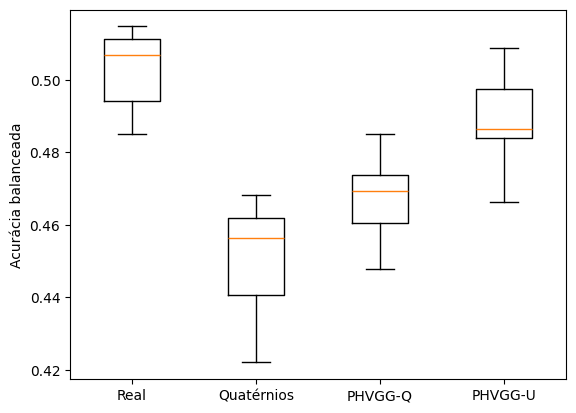

In [ ]:
import matplotlib.pyplot as plt
def boxplot_acuracia_balanceada(metricas):
    dados = [
        metricas['Real_Balanced_Accuracy'],
        metricas['Quat_Balanced_Accuracy'],
        metricas['PHVGG_Q_Balanced_Accuracy'],
        metricas['PHVGG_U_Balanced_Accuracy']
    ]

    plt.boxplot(dados)
    plt.xticks([1, 2, 3, 4], ['Real', 'Quatérnios', 'PHVGG-Q', 'PHVGG-U'])
    plt.ylabel('Acurácia balanceada')
    plt.show()

#metricas = local, metricas_externas = arquivo externo
boxplot_acuracia_balanceada(metricas_externas)

### Baixar os arquivos do Colab


In [ ]:
# from google.colab import files
# files.download('resultados_cifar10.csv')
# files.download('algebras_cifar10.csv')

FileNotFoundError: Cannot find file: algebras_cifar10.csv